<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="Vector Gateway Interface" width="170"></a>

# Where does the reported holdings weight sit?

A fund can report hundreds of holding rows while much of its weight sits in a smaller group. We will compare **RSP** and **SPHQ**, using Invesco’s reported current holdings, and ask how much positive reported weight appears in the largest `N` rows. We will also trace the whole weight distribution rather than treating row count alone as concentration.

The default uses **unchanged official responses recorded on November 14, 2026**, with holdings effective November 12. The real released VGI worker parses those responses. They are not synthetic data, and replay does not provide historical access to Invesco: its holdings endpoint is current-only. This is a descriptive data exercise, not a return forecast, risk measure or fund recommendation. [Setup, provenance and limitations](README.md).

## Choose the number of rows

`TOP_N` counts holding **rows**, not issuers or economic exposures. Accepted range: 1–100, subject to each response containing at least that many positive-weight rows. `DATA_MODE="recorded"` uses the fixed three-response recording. `"live"` requests the current official catalog and the same two funds, with source dates shown in the results. No date window is accepted because current holdings cannot be requested at an arbitrary past date.

Edit, restart the kernel, and run all. The end experiment changes only `TOP_N` from 10 to 25.

In [1]:
TOP_N = 10  # largest positive-weight holding rows per fund, integer 1..100
DATA_MODE = "recorded"  # recorded or live

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme, verify_audit

previous, audit, run_at = configure(TOP_N, DATA_MODE)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = False
%sql connection
connection.execute("CREATE TABLE settings AS SELECT ?::INTEGER AS top_n", [TOP_N])

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-invesco-portable-vne3qh31/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-invesco-portable-vne3qh31/pyproject.toml.

## Connect to the released worker

The literal launcher clones the immutable source revision behind `v0.4.0`, installs its frozen Bun lock, and adds a small notebook transport adapter. The existing worker’s function factories, catalog, parsing and partition-filter code are unchanged. In recorded mode the adapter verifies response hashes and returns their exact bytes through the client’s existing fetch seam. In live mode it uses the normal official HTTPS client. It never computes holdings or silently substitutes recorded responses. Git, Bun and first-use network access are required; this repository’s worker checkout is not used.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'invesco' (TYPE vgi, LOCATION 'bash launch_worker.sh');

,Success


## Fetch only the two requested funds

The literal `fund_ticker IN (...)` filter reaches the holdings worker and bounds its remote work. The catalog is materialized once, and all later joins use local in-memory tables. This avoids accidentally scanning the issuer’s entire fund lineup through an unpushed join. `fund_ticker` is the fund identifier; `ticker` inside a holding row is a constituent identifier.

The released worker tolerates failed or empty holdings partitions. Therefore we explicitly require both requested funds below; an omitted fund must not appear as a zero-weight portfolio.

In [4]:
%%sql
CREATE TABLE requested AS SELECT * FROM (VALUES ('RSP'), ('SPHQ')) AS t(fund_ticker);
CREATE TABLE products AS
SELECT ticker, name, base_currency, investment_method FROM invesco.products
WHERE ticker IN ('RSP','SPHQ');
CREATE TABLE holdings AS
SELECT * FROM invesco.holdings WHERE fund_ticker IN ('RSP','SPHQ');
SELECT p.*, count(h.fund_ticker) AS holding_rows,
       min(h.as_of_date) AS first_source_date, max(h.as_of_date) AS last_source_date
FROM requested r LEFT JOIN products p ON p.ticker = r.fund_ticker
LEFT JOIN holdings h ON h.fund_ticker = r.fund_ticker
GROUP BY ALL ORDER BY p.ticker;

,ticker,name,base_currency,investment_method,holding_rows,first_source_date,last_source_date
0,RSP,Invesco S&P 500 Equal Weight ETF,USD,Passive,511,2026-11-12,2026-11-12
1,SPHQ,Invesco S&P 500 Quality ETF,USD,Passive,105,2026-11-12,2026-11-12


## Audit the weight denominator

`weight_percent=0.33` means **0.33 percentage points of reported net assets**, not a fraction of 0.33. Keep positive, zero, negative and missing weights separate. Negative lines may be offsets or liabilities; missing values are unknown. We display their totals rather than discard them without notice.

The concentration calculation is conditional on **known positive-weight rows**. It is not a complete exposure measure and does not aggregate duplicate issuers, share classes or derivatives. Summing the reported weights need not equal exactly 100 because of rounding, cash, liabilities or incomplete source data. We do not force that total to 100.

In [5]:
%%sql
CREATE TABLE diagnostics AS
SELECT r.fund_ticker, p.name, p.base_currency,
       count(h.fund_ticker) AS row_count,
       count(h.weight_percent) AS known_count,
       count(h.fund_ticker) FILTER (WHERE h.weight_percent IS NULL) AS missing_count,
       count(*) FILTER (WHERE h.weight_percent = 0) AS zero_count,
       count(*) FILTER (WHERE h.weight_percent < 0) AS negative_count,
       count(*) FILTER (WHERE h.weight_percent > 0) AS positive_count,
       sum(h.weight_percent) AS reported_net_percent,
       sum(h.weight_percent) FILTER (WHERE h.weight_percent > 0) AS positive_percent,
       coalesce(sum(h.weight_percent) FILTER (WHERE h.weight_percent < 0),0) AS negative_percent,
       min(h.as_of_date) AS source_date, count(DISTINCT h.as_of_date) AS source_dates,
       count(h.fund_ticker) FILTER (WHERE h.as_of_date IS NULL) AS undated_count
FROM requested r LEFT JOIN products p ON p.ticker = r.fund_ticker
LEFT JOIN holdings h ON h.fund_ticker = r.fund_ticker
GROUP BY r.fund_ticker, p.name, p.base_currency;
SELECT * FROM diagnostics ORDER BY fund_ticker;

,fund_ticker,name,base_currency,row_count,known_count,missing_count,zero_count,negative_count,positive_count,reported_net_percent,positive_percent,negative_percent,source_date,source_dates,undated_count
0,RSP,Invesco S&P 500 Equal Weight ETF,USD,511,510,1,2,2,506,100.000012,100.190933,-0.190921,2026-11-12,1,0
1,SPHQ,Invesco S&P 500 Quality ETF,USD,105,104,1,1,2,101,99.999996,100.002027,-0.002031,2026-11-12,1,0


In [6]:
diagnostics = connection.execute("SELECT * FROM diagnostics ORDER BY fund_ticker").df()
assert len(diagnostics) == 2 and diagnostics.row_count.gt(0).all(), "A requested fund is absent or empty"
assert diagnostics.positive_count.ge(TOP_N).all(), "TOP_N exceeds a fund's positive-weight row count"
assert diagnostics.source_dates.eq(1).all() and diagnostics.undated_count.eq(0).all(), (
    "Mixed or missing dates"
)
assert diagnostics.positive_percent.gt(0).all(), "Positive-weight denominator is unavailable"
assert diagnostics.name.notna().all(), "Requested fund is absent from the product catalog"
mode_label = "Recorded official responses" if DATA_MODE == "recorded" else "Live official responses"
date_labels = "; ".join(f"{r.fund_ticker}: {r.source_date:%Y-%m-%d}" for r in diagnostics.itertuples())
prose(
    f"**{mode_label}.** Source dates: {date_labels}. "
    + (
        "Both funds report the same date. "
        if diagnostics.source_date.nunique() == 1
        else "Dates differ: the comparison spans different snapshots. "
    )
    + "These are calendar dates, not timestamps. Capture/run time is distinct from the effective date. "
    + f"This execution began at `{run_at}`."
)
prose(verify_audit(DATA_MODE, audit))

**Recorded official responses.** Source dates: RSP: 2026-11-12; SPHQ: 2026-11-12. Both funds report the same date. These are calendar dates, not timestamps. Capture/run time is distinct from the effective date. This execution began at `2026-11-14T06:52:09.693789+00:00`.

Recorded request audit passed: one catalog and exactly one holdings response for each selected fund.

## Rank positive rows and normalize explicitly

For positive reported weights \(w_i\), define \(W_+=\sum_i w_i\) and \(p_i=w_i/W_+\). The largest-\(N\) sum is still in reported net-asset percentage points. Dividing it by \(W_+\) gives its share **of the positive reported weight**, a different denominator.

The concentration index \(H=\sum_i p_i^2\) is dimensionless; \(1/H\) is the effective number of equally weighted rows that would produce the same index. This row-level summary does not measure diversification of issuers, industries or economic risks. SQL computes both forms and keeps the denominator visible. Ties use the available row descriptors; identical rows are interchangeable for these weight sums.

In [7]:
%%sql
CREATE TABLE ranked AS
SELECT h.*, d.positive_percent, d.positive_count,
       h.weight_percent / d.positive_percent AS positive_share,
       row_number() OVER (
         PARTITION BY h.fund_ticker
         ORDER BY h.weight_percent DESC, h.name NULLS LAST, h.ticker NULLS LAST,
                  h.cusip NULLS LAST, h.sec_type NULLS LAST, h.currency NULLS LAST
       ) AS rank
FROM holdings h JOIN diagnostics d USING (fund_ticker) WHERE h.weight_percent > 0;
CREATE TABLE curves AS
SELECT *, sum(weight_percent) OVER (PARTITION BY fund_ticker ORDER BY rank) AS cumulative_percent,
       sum(positive_share) OVER (PARTITION BY fund_ticker ORDER BY rank) AS cumulative_positive_share,
       rank::DOUBLE / positive_count AS row_fraction
FROM ranked;
CREATE TABLE summary AS
SELECT r.fund_ticker, max(r.positive_count) AS positive_count,
       max(r.positive_percent) AS positive_percent,
       sum(r.weight_percent) FILTER (WHERE r.rank <= s.top_n) AS top_n_percent,
       sum(r.positive_share) FILTER (WHERE r.rank <= s.top_n) AS top_n_positive_share,
       sum(r.positive_share ^ 2) AS concentration_index,
       1 / sum(r.positive_share ^ 2) AS effective_rows
FROM ranked r CROSS JOIN settings s GROUP BY r.fund_ticker;
SELECT *, (SELECT top_n FROM settings) AS selected_n FROM summary ORDER BY fund_ticker;

,fund_ticker,positive_count,positive_percent,top_n_percent,top_n_positive_share,concentration_index,effective_rows,selected_n
0,RSP,506,100.190933,2.688076,0.026830,0.002024,494.035794,10
1,SPHQ,101,100.002027,44.195533,0.441946,0.027976,35.745403,10


In [8]:
%%sql
SELECT fund_ticker, rank, name, ticker, sec_type, weight_percent
FROM ranked WHERE rank <= 5 ORDER BY fund_ticker, rank;

,fund_ticker,rank,name,ticker,sec_type,weight_percent
0,RSP,1,Moderna Inc,MRNA,Common Stock,0.330920
1,RSP,2,PTC Inc,PTC,Common Stock,0.295213
2,RSP,3,Accenture PLC,ACN,Common Stock,0.277422
3,RSP,4,Hasbro Inc,HAS,Common Stock,0.264854
4,RSP,5,IDEXX Laboratories Inc,IDXX,Common Stock,0.262688
5,SPHQ,1,Mastercard Inc,MA,Common Stock,6.646953
6,SPHQ,2,Visa Inc,V,Common Stock,6.494922
7,SPHQ,3,Apple Inc,AAPL,Common Stock,6.067413
8,SPHQ,4,Costco Wholesale Corp,COST,Common Stock,4.648999
9,SPHQ,5,General Electric Co,GE,Common Stock,3.679950


## Verify the relationships

These checks test identities and coverage rather than assuming the two funds have a particular ranking or holdings count. Floating-point sums use small tolerances. In particular, reconstructing `H` directly from the raw squared weights must agree with summing normalized squares. The cumulative curve must end at the observed positive total, not a forced 100% of net assets.

In [9]:
%%sql checks <<
SELECT 'both requested funds and no others were returned' AS invariant,
       NOT EXISTS (SELECT * FROM requested ANTI JOIN holdings USING (fund_ticker))
       AND NOT EXISTS (SELECT * FROM holdings ANTI JOIN requested USING (fund_ticker)) AS passed
UNION ALL SELECT 'reported weights are finite when known',
       (SELECT bool_and(NOT isnan(weight_percent) AND NOT isinf(weight_percent)) FROM holdings WHERE weight_percent IS NOT NULL)
UNION ALL SELECT 'weight categories reconcile to row count',
       (SELECT bool_and(positive_count + zero_count + negative_count + missing_count = row_count) FROM diagnostics)
UNION ALL SELECT 'positive and negative totals reconstruct known net weight',
       (SELECT bool_and(abs(positive_percent + negative_percent - reported_net_percent) < 1e-8) FROM diagnostics)
UNION ALL SELECT 'positive shares sum to one',
       (SELECT bool_and(abs(total - 1) < 1e-10) FROM (SELECT sum(positive_share) AS total FROM ranked GROUP BY fund_ticker))
UNION ALL SELECT 'raw and normalized concentration agree',
       (SELECT bool_and(abs(raw_index - concentration_index) < 1e-12) FROM summary JOIN
         (SELECT fund_ticker, sum(weight_percent^2) / max(positive_percent)^2 AS raw_index FROM ranked GROUP BY fund_ticker) USING(fund_ticker))
UNION ALL SELECT 'effective row count lies between one and observed positive rows',
       (SELECT bool_and(effective_rows >= 1 - 1e-8 AND effective_rows <= positive_count + 1e-8) FROM summary)
UNION ALL SELECT 'top-N sum and cumulative endpoint agree',
       (SELECT bool_and(abs(s.top_n_percent - c.cumulative_percent) < 1e-8
                        AND abs(s.top_n_positive_share - c.cumulative_positive_share) < 1e-10)
        FROM summary s JOIN curves c USING(fund_ticker) CROSS JOIN settings p WHERE c.rank = p.top_n)
UNION ALL SELECT 'full cumulative curve reaches positive total',
       (SELECT bool_and(abs(cumulative_percent - positive_percent) < 1e-8 AND abs(cumulative_positive_share - 1) < 1e-10)
        FROM curves WHERE rank = positive_count)
UNION ALL SELECT 'largest-row cumulative share dominates equal weighting',
       (SELECT bool_and(cumulative_positive_share + 1e-10 >= row_fraction) FROM curves);

In [10]:
display(checks)
assert checks.passed.fillna(False).all(), "A holdings identity failed"
summary = connection.execute("SELECT * FROM summary ORDER BY fund_ticker").df()
curves = connection.execute("SELECT * FROM curves ORDER BY fund_ticker, rank").df()
for row in summary.itertuples():
    d = diagnostics[diagnostics.fund_ticker == row.fund_ticker].iloc[0]
    prose(
        f"**{row.fund_ticker}:** largest {TOP_N} rows sum to **{row.top_n_percent:.2f} percentage points** "
        f"of reported net assets, or **{row.top_n_positive_share:.2%}** "
        f"of its {row.positive_percent:.3f}-point positive total. "
        f"There are {row.positive_count:.0f} positive rows; "
        f"the effective equally weighted count is **{row.effective_rows:.1f}**. "
        f"Separately, {d.negative_count:.0f} negative rows sum to {d.negative_percent:.3f} points; "
        f"{d.zero_count:.0f} rows have zero weight and {d.missing_count:.0f} have unknown weight."
    )

,invariant,passed
0,both requested funds and no others were returned,True
1,reported weights are finite when known,True
2,weight categories reconcile to row count,True
3,positive and negative totals reconstruct known...,True
4,positive shares sum to one,True
5,raw and normalized concentration agree,True
6,effective row count lies between one and obser...,True
7,top-N sum and cumulative endpoint agree,True
8,full cumulative curve reaches positive total,True
9,largest-row cumulative share dominates equal w...,True


**RSP:** largest 10 rows sum to **2.69 percentage points** of reported net assets, or **2.68%** of its 100.191-point positive total. There are 506 positive rows; the effective equally weighted count is **494.0**. Separately, 2 negative rows sum to -0.191 points; 2 rows have zero weight and 1 have unknown weight.

**SPHQ:** largest 10 rows sum to **44.20 percentage points** of reported net assets, or **44.19%** of its 100.002-point positive total. There are 101 positive rows; the effective equally weighted count is **35.7**. Separately, 2 negative rows sum to -0.002 points; 1 rows have zero weight and 1 have unknown weight.

## Separate the largest rows from the rest

The bar length is the actual positive-weight total in percentage points of reported net assets. Amber identifies the largest `N` rows; the pale segment is the remaining positive weight. Negative and unknown rows are reported above and are outside these bars. This is why the axis does not call every complete bar “100% of the fund.”

findfont: Failed to find font weight semibold for Arial, now using 700.


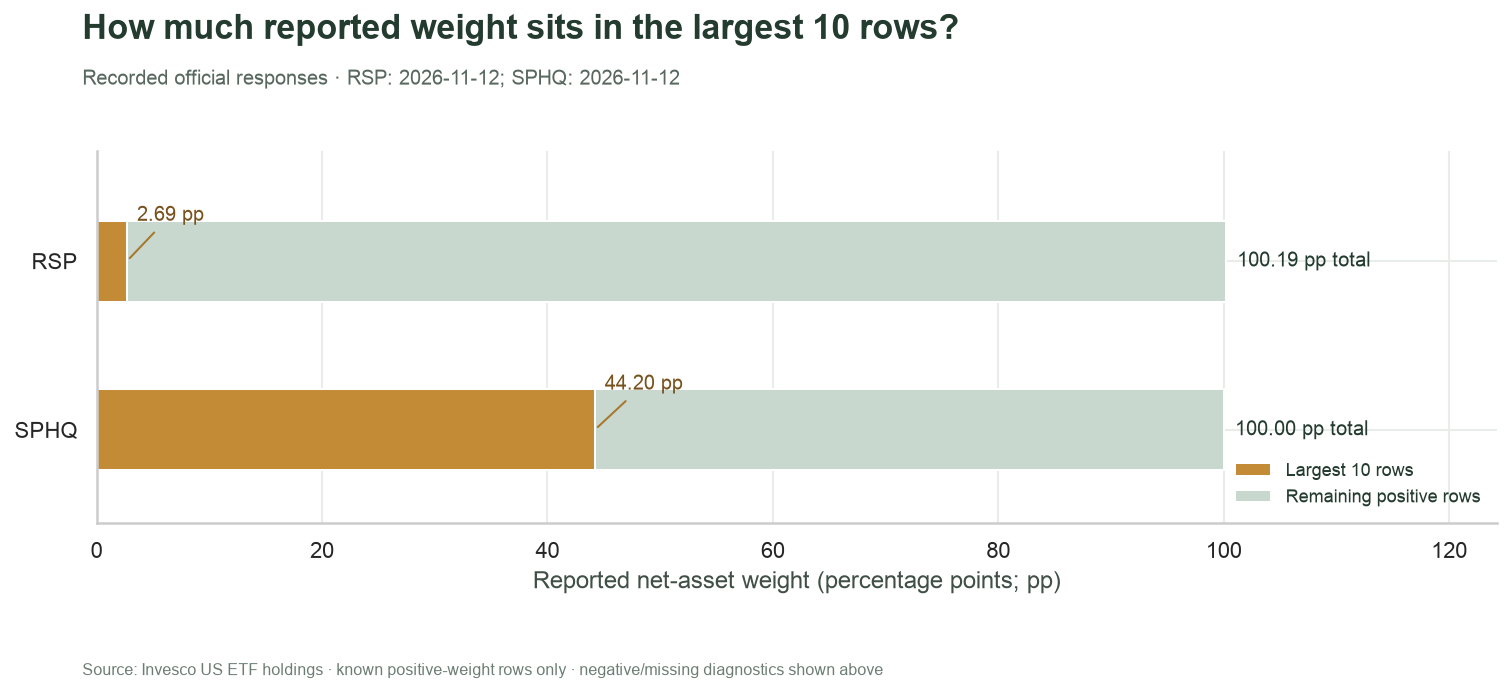

In [11]:
fig, ax = plt.subplots(figsize=(10.8, 4.8))
y = np.arange(len(summary))
rest = summary.positive_percent - summary.top_n_percent
ax.barh(y, summary.top_n_percent, color="#C48B37", height=0.48, label=f"Largest {TOP_N} rows")
ax.barh(y, rest, left=summary.top_n_percent, color="#C8D8CE", height=0.48, label="Remaining positive rows")
for pos, row in zip(y, summary.itertuples(), strict=True):
    ax.annotate(
        f"{row.top_n_percent:.2f} pp",
        (row.top_n_percent, pos),
        xytext=(5, 20),
        textcoords="offset points",
        fontsize=10,
        color="#78521D",
        arrowprops={"arrowstyle": "-", "color": "#A7772B"},
    )
    ax.text(row.positive_percent + 1, pos, f"{row.positive_percent:.2f} pp total", va="center", fontsize=10)
ax.set_yticks(y, summary.fund_ticker)
ax.invert_yaxis()
ax.set_xlim(0, summary.positive_percent.max() * 1.24)
ax.set_ylim(len(summary) - 0.45, -0.65)
ax.set_xlabel("Reported net-asset weight (percentage points; pp)")
ax.legend(loc="lower right", fontsize=9)
chart(
    fig,
    f"How much reported weight sits in the largest {TOP_N} rows?",
    f"{mode_label} · {date_labels}",
    "Source: Invesco US ETF holdings · known positive-weight rows only · "
    "negative/missing diagnostics shown above",
)

## Compare the complete distributions

Each curve orders positive-weight rows from largest to smallest. Its horizontal coordinate is the fraction of those rows included; its vertical coordinate is the share of their positive weight. The diagonal is a hypothetical equal-weight allocation across the same number of rows. The highlighted point marks `TOP_N`, so it lands at a different horizontal position for funds with different row counts. The concentration index uses the whole curve’s weights and does not depend on that selected cutoff.

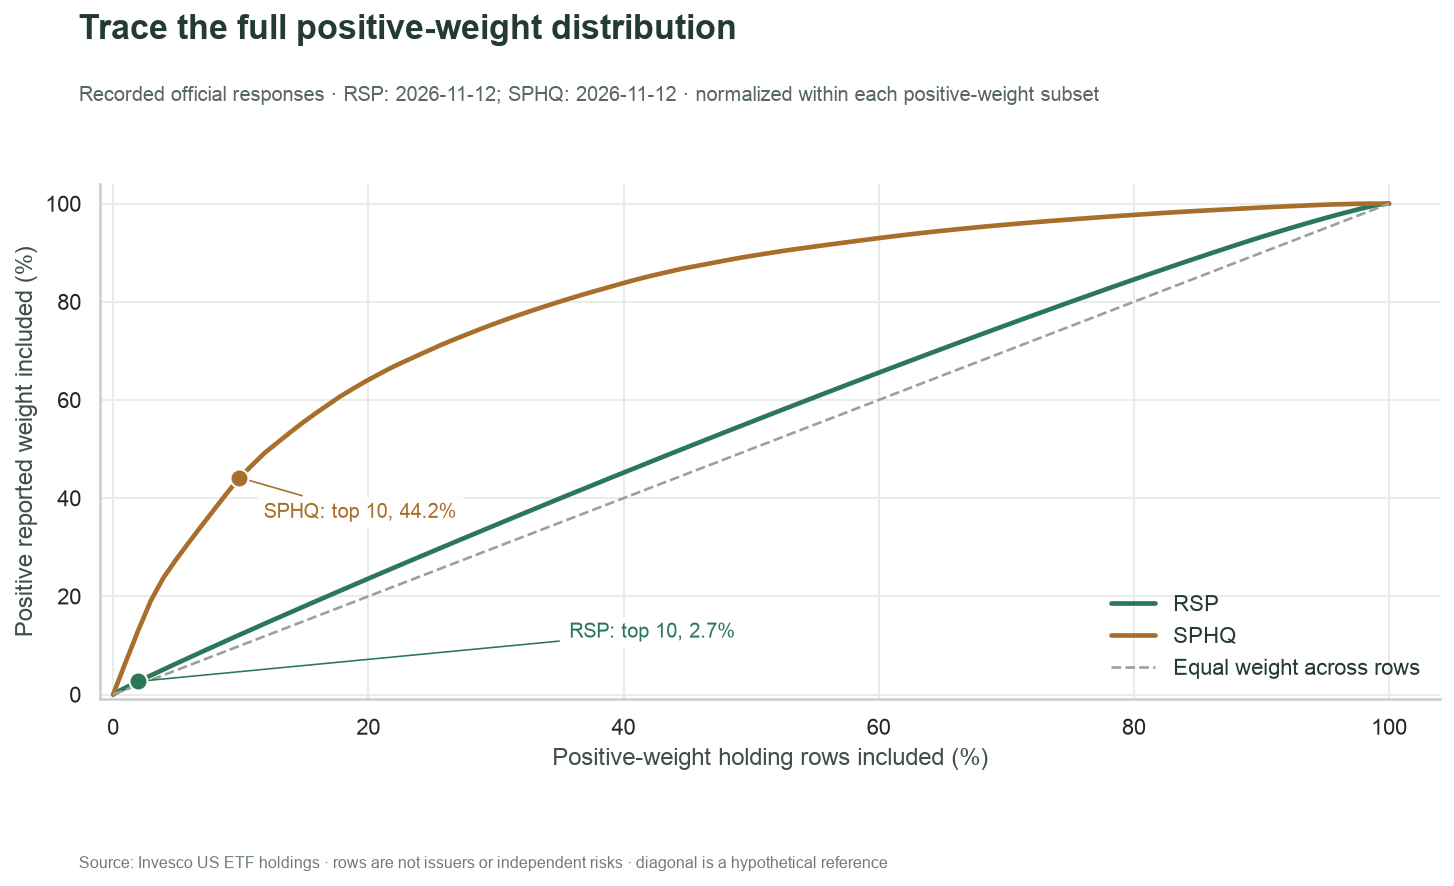

In [12]:
fig, ax = plt.subplots(figsize=(10.4, 6.2))
colors = {"RSP": "#2A7857", "SPHQ": "#A86E2B"}
for ticker, part in curves.groupby("fund_ticker", sort=True):
    ax.plot(
        np.r_[0, part.row_fraction.to_numpy() * 100],
        np.r_[0, part.cumulative_positive_share.to_numpy() * 100],
        color=colors[ticker],
        linewidth=2.3,
        label=ticker,
    )
    chosen = part[part["rank"] == TOP_N].iloc[0]
    ax.scatter(
        chosen.row_fraction * 100,
        chosen.cumulative_positive_share * 100,
        s=80,
        color=colors[ticker],
        edgecolor="white",
        zorder=4,
    )
    ax.annotate(
        f"{ticker}: top {TOP_N}, {chosen.cumulative_positive_share:.1%}",
        (chosen.row_fraction * 100, chosen.cumulative_positive_share * 100),
        xytext=(0.35, 0.12) if ticker == "RSP" else (-12 if chosen.row_fraction > 0.7 else 12, -20),
        textcoords="axes fraction" if ticker == "RSP" else "offset points",
        ha="right" if ticker == "SPHQ" and chosen.row_fraction > 0.7 else "left",
        color=colors[ticker],
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.95, "pad": 3},
        arrowprops={"arrowstyle": "-", "color": colors[ticker], "linewidth": 0.8},
    )
ax.plot([0, 100], [0, 100], color="#96A29A", linestyle="--", linewidth=1.3, label="Equal weight across rows")
ax.set_xlim(-1, 104)
ax.set_ylim(-1, 104)
ax.set_xlabel("Positive-weight holding rows included (%)")
ax.set_ylabel("Positive reported weight included (%)")
ax.legend(loc="lower right")
chart(
    fig,
    "Trace the full positive-weight distribution",
    f"{mode_label} · {date_labels} · normalized within each positive-weight subset",
    "Source: Invesco US ETF holdings · rows are not issuers or independent risks · "
    "diagonal is a hypothetical reference",
)

## Experiment: expand the largest-row group

Change **`TOP_N` from 10 to 25**, restart and run all. Predict that the selected weight cannot decrease: the added rows all have positive reported weights. Compare the amber bar segments, the selected curve points and the top-N percentages. The recorded rows, source dates, totals, complete curves and effective row counts should stay fixed. Reset `TOP_N = 10` afterward. Use the separate-output command in the README to preserve the default.

Changing to live mode is a different experiment: the issuer may publish new holdings or different effective dates. A change in totals then mixes time and selection effects. Neither version supports claims about future returns, tracking quality or economic diversification from row weights alone.

In [13]:
connection.close()
cleanup(previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>